# Alfido Tech — Task 1: Customer Behavior Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

sns.set_theme(style="whitegrid")

df = pd.read_csv("ecommerce_customer_data_custom_ratios.csv")

print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nMissing Values:\n", df.isnull().sum())
print("\nDuplicates:", df.duplicated().sum())
df.head()

Shape: (250000, 13)

Columns: ['Customer ID', 'Purchase Date', 'Product Category', 'Product Price', 'Quantity', 'Total Purchase Amount', 'Payment Method', 'Customer Age', 'Returns', 'Customer Name', 'Age', 'Gender', 'Churn']

Missing Values:
 Customer ID                  0
Purchase Date                0
Product Category             0
Product Price                0
Quantity                     0
Total Purchase Amount        0
Payment Method               0
Customer Age                 0
Returns                  47596
Customer Name                0
Age                          0
Gender                       0
Churn                        0
dtype: int64

Duplicates: 0


,Customer ID,Purchase Date,Product Category,Product Price,Quantity,Total Purchase Amount,Payment Method,Customer Age,Returns,Customer Name,Age,Gender,Churn
0,46251,2020-09-08 09:38:32,Electronics,12,3,740,Credit Card,37,0.0,Christine Hernandez,37,Male,0
1,46251,2022-03-05 12:56:35,Home,468,4,2739,PayPal,37,0.0,Christine Hernandez,37,Male,0
2,46251,2022-05-23 18:18:01,Home,288,2,3196,PayPal,37,0.0,Christine Hernandez,37,Male,0
3,46251,2020-11-12 13:13:29,Clothing,196,1,3509,PayPal,37,0.0,Christine Hernandez,37,Male,0
4,13593,2020-11-27 17:55:11,Home,449,1,3452,Credit Card,49,0.0,James Grant,49,Female,1


In [2]:
# 1. Verify if 'Age' and 'Customer Age' are identical, then drop 'Age'
print("Age == Customer Age everywhere:", (df["Age"] == df["Customer Age"]).all())
df = df.drop(columns=["Age"])

# 2. Convert Purchase Date to datetime
df["Purchase Date"] = pd.to_datetime(df["Purchase Date"])

# 3. Handle missing Returns (47,596 NaNs -> assume 0 = No Return, plus keep a flag if needed)
df["Returns"] = df["Returns"].fillna(0).astype(int)

# 4. Verify Total Purchase Amount vs Product Price * Quantity
df["Calculated_Item_Total"] = df["Product Price"] * df["Quantity"]
mismatch_pct = (df["Total Purchase Amount"] != df["Calculated_Item_Total"]).mean() * 100
print(f"Rows where Total Purchase Amount != Price * Qty: {mismatch_pct:.2f}%")

# 5. Feature Engineering: Date parts & Age Groups
df["Year"] = df["Purchase Date"].dt.year
df["Month"] = df["Purchase Date"].dt.month
df["YearMonth"] = df["Purchase Date"].dt.to_period("M").astype(str)
df["DayOfWeek"] = df["Purchase Date"].dt.day_name()

df["Age_Group"] = pd.cut(
    df["Customer Age"],
    bins=[0, 25, 35, 45, 55, 100],
    labels=["18-25", "26-35", "36-45", "46-55", "56+"]
)

# 6. Print headline KPIs for your PDF Executive Summary
print("\n--- HEADLINE KPIs ---")
print(f"Date Range: {df['Purchase Date'].min().date()} to {df['Purchase Date'].max().date()}")
print(f"Unique Customers: {df['Customer ID'].nunique():,}")
print(f"Total Transactions: {len(df):,}")
print(f"Total Revenue: ${df['Total Purchase Amount'].sum():,.2f}")
print(f"Average Order Value (AOV): ${df['Total Purchase Amount'].mean():,.2f}")
print(f"Overall Return Rate: {df['Returns'].mean() * 100:.2f}%")
print(f"Overall Customer Churn Rate: {df.groupby('Customer ID')['Churn'].max().mean() * 100:.2f}%")
print("\nMissing values remaining:", df.isnull().sum().sum())

Age == Customer Age everywhere: True
Rows where Total Purchase Amount != Price * Qty: 99.98%

--- HEADLINE KPIs ---
Date Range: 2020-01-01 to 2023-09-15
Unique Customers: 49,673
Total Transactions: 250,000
Total Revenue: $681,342,683.00
Average Order Value (AOV): $2,725.37
Overall Return Rate: 40.31%
Overall Customer Churn Rate: 20.01%

Missing values remaining: 0


In [3]:
# Set snapshot date to 1 day after the latest purchase in the dataset
snapshot_date = df["Purchase Date"].max() + pd.Timedelta(days=1)

# Aggregate to customer level
rfm = df.groupby("Customer ID").agg(
    Recency=("Purchase Date", lambda x: (snapshot_date - x.max()).days),
    Frequency=("Purchase Date", "count"),
    Monetary=("Total Purchase Amount", "sum"),
    Avg_Order_Value=("Total Purchase Amount", "mean"),
    Return_Rate=("Returns", "mean"),
    Churn=("Churn", "max"),
    Customer_Age=("Customer Age", "first"),
    Gender=("Gender", "first")
).reset_index()

# Assign quartile scores (1 to 4)
rfm["R_Score"] = pd.qcut(rfm["Recency"], 4, labels=[4, 3, 2, 1]).astype(int)
rfm["F_Score"] = pd.qcut(rfm["Frequency"].rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)
rfm["M_Score"] = pd.qcut(rfm["Monetary"].rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)

# Map RFM scores to business segments
def assign_segment(row):
    if row["R_Score"] >= 3 and row["F_Score"] >= 3 and row["M_Score"] >= 3:
        return "Champions"
    elif row["F_Score"] >= 3 and row["R_Score"] >= 2:
        return "Loyal Customers"
    elif row["R_Score"] <= 2 and row["M_Score"] >= 3:
        return "At-Risk High Value"
    elif row["R_Score"] == 4 and row["F_Score"] <= 2:
        return "New / Promising"
    elif row["R_Score"] == 1:
        return "Lost / Hibernating"
    else:
        return "Regular / Occasional"

rfm["Segment"] = rfm.apply(assign_segment, axis=1)

# Profile each segment
segment_profile = rfm.groupby("Segment").agg(
    Customers=("Customer ID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Total_Revenue=("Monetary", "sum"),
    Churn_Rate_Pct=("Churn", lambda x: x.mean() * 100),
    Return_Rate_Pct=("Return_Rate", lambda x: x.mean() * 100)
).round(2).sort_values("Total_Revenue", ascending=False)

segment_profile["Customer_Share_Pct"] = (
    segment_profile["Customers"] / segment_profile["Customers"].sum() * 100
).round(2)
segment_profile["Revenue_Share_Pct"] = (
    segment_profile["Total_Revenue"] / segment_profile["Total_Revenue"].sum() * 100
).round(2)

segment_profile

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue,Churn_Rate_Pct,Return_Rate_Pct,Customer_Share_Pct,Revenue_Share_Pct
Segment,,,,,,,,,
Champions,13156,79.68,7.21,20410.74,268523666,19.35,40.40,26.49,39.41
Loyal Customers,8523,214.09,6.31,16031.28,136634598,20.30,40.34,17.16,20.05
Regular / Occasional,10117,201.31,3.39,8915.51,90198226,20.19,40.08,20.37,13.24
At-Risk High Value,4604,463.45,5.40,16859.53,77621294,19.61,40.27,9.27,11.39
Lost / Hibernating,8884,649.43,2.95,7308.04,64924628,20.07,39.37,17.88,9.53
New / Promising,4389,39.40,3.64,9897.53,43440271,21.35,40.73,8.84,6.38


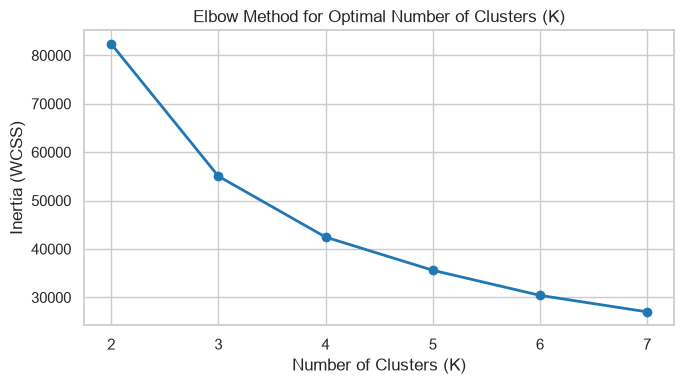

--- K-MEANS CLUSTER PROFILE (K=4) ---


,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Churn_Rate_Pct
Cluster,,,,,
0,8389,136.84,8.44,24494.15,20.25
1,18723,183.65,5.72,15614.06,19.75
2,14912,194.01,3.33,8292.91,20.27
3,7649,719.85,2.94,7825.25,19.92


In [4]:
# Standardize Recency, Frequency, and Monetary for K-Means
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm[["Recency", "Frequency", "Monetary"]])

# Elbow Method
inertias = []
for k in range(2, 8):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(rfm_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(2, 8), inertias, marker="o", linewidth=2, color="#1f77b4")
plt.title("Elbow Method for Optimal Number of Clusters (K)")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (WCSS)")
plt.tight_layout()
plt.savefig("chart_elbow.png", dpi=300)
plt.show()

# Fit K-Means with K=4
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

cluster_summary = rfm.groupby("Cluster").agg(
    Customers=("Customer ID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Churn_Rate_Pct=("Churn", lambda x: x.mean() * 100)
).round(2)

print("--- K-MEANS CLUSTER PROFILE (K=4) ---")
cluster_summary

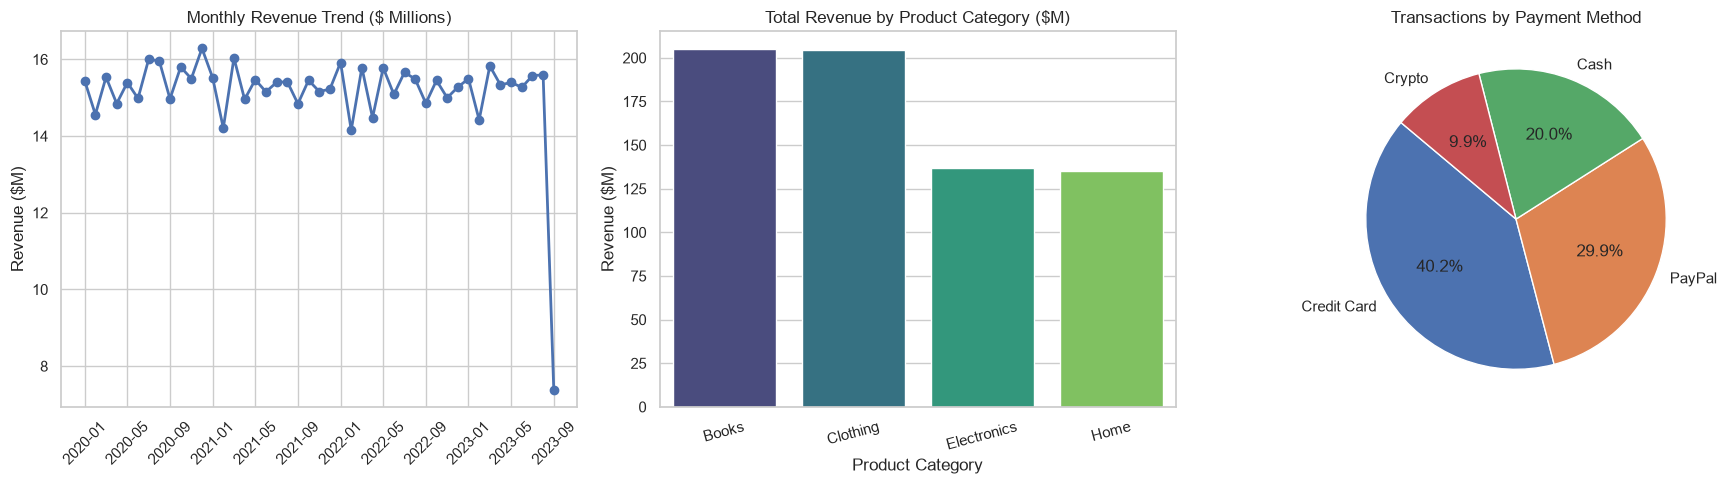

--- PRODUCT CATEGORY BREAKDOWN ---
                  Orders    Revenue  Avg_Order_Value  Return_Rate_Pct  \
Product Category                                                        
Books              74912  204939601          2735.74            40.35   
Clothing           75052  204532405          2725.21            40.13   
Electronics        50185  136599467          2721.92            40.39   
Home               49851  135271210          2713.51            40.41   

                  Churn_Rate_Pct  Revenue_Share_Pct  
Product Category                                     
Books                      19.92              30.08  
Clothing                   19.85              30.02  
Electronics                19.88              20.05  
Home                       20.20              19.85  

--- PAYMENT METHOD SHARE (%) ---
Payment Method
Credit Card    40.19
PayPal         29.93
Cash           19.96
Crypto          9.91
Name: proportion, dtype: float64

--- AGE GROUP BREAKDOWN ---
       

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Monthly Revenue Trend
monthly_sales = df.groupby("YearMonth")["Total Purchase Amount"].sum().reset_index()
axes[0].plot(monthly_sales["YearMonth"], monthly_sales["Total Purchase Amount"] / 1e6, marker="o", linewidth=2)
axes[0].set_title("Monthly Revenue Trend ($ Millions)")
axes[0].set_ylabel("Revenue ($M)")
axes[0].tick_params(axis="x", rotation=45)
axes[0].set_xticks(range(0, len(monthly_sales), 4))
axes[0].set_xticklabels(monthly_sales["YearMonth"].iloc[::4], rotation=45)

# 2. Revenue by Product Category
cat_sales = df.groupby("Product Category")["Total Purchase Amount"].sum().sort_values(ascending=False)
sns.barplot(x=cat_sales.index, y=cat_sales.values / 1e6, ax=axes[1], hue=cat_sales.index, palette="viridis", legend=False)
axes[1].set_title("Total Revenue by Product Category ($M)")
axes[1].set_ylabel("Revenue ($M)")
axes[1].tick_params(axis="x", rotation=15)

# 3. Payment Method Share
pay_counts = df["Payment Method"].value_counts()
axes[2].pie(pay_counts.values, labels=pay_counts.index, autopct="%1.1f%%", startangle=140)
axes[2].set_title("Transactions by Payment Method")

plt.tight_layout()
plt.savefig("chart_purchase_patterns.png", dpi=300)
plt.show()

# Print exact breakdown tables for the PDF report
print("--- PRODUCT CATEGORY BREAKDOWN ---")
cat_summary = df.groupby("Product Category").agg(
    Orders=("Customer ID", "count"),
    Revenue=("Total Purchase Amount", "sum"),
    Avg_Order_Value=("Total Purchase Amount", "mean"),
    Return_Rate_Pct=("Returns", lambda x: x.mean() * 100),
    Churn_Rate_Pct=("Churn", lambda x: x.mean() * 100)
).round(2).sort_values("Revenue", ascending=False)
cat_summary["Revenue_Share_Pct"] = (cat_summary["Revenue"] / cat_summary["Revenue"].sum() * 100).round(2)
print(cat_summary)

print("\n--- PAYMENT METHOD SHARE (%) ---")
print((df["Payment Method"].value_counts(normalize=True) * 100).round(2))

print("\n--- AGE GROUP BREAKDOWN ---")
age_summary = df.groupby("Age_Group", observed=False).agg(
    Orders=("Customer ID", "count"),
    Revenue=("Total Purchase Amount", "sum"),
    Churn_Rate_Pct=("Churn", lambda x: x.mean() * 100)
).round(2)
print(age_summary)

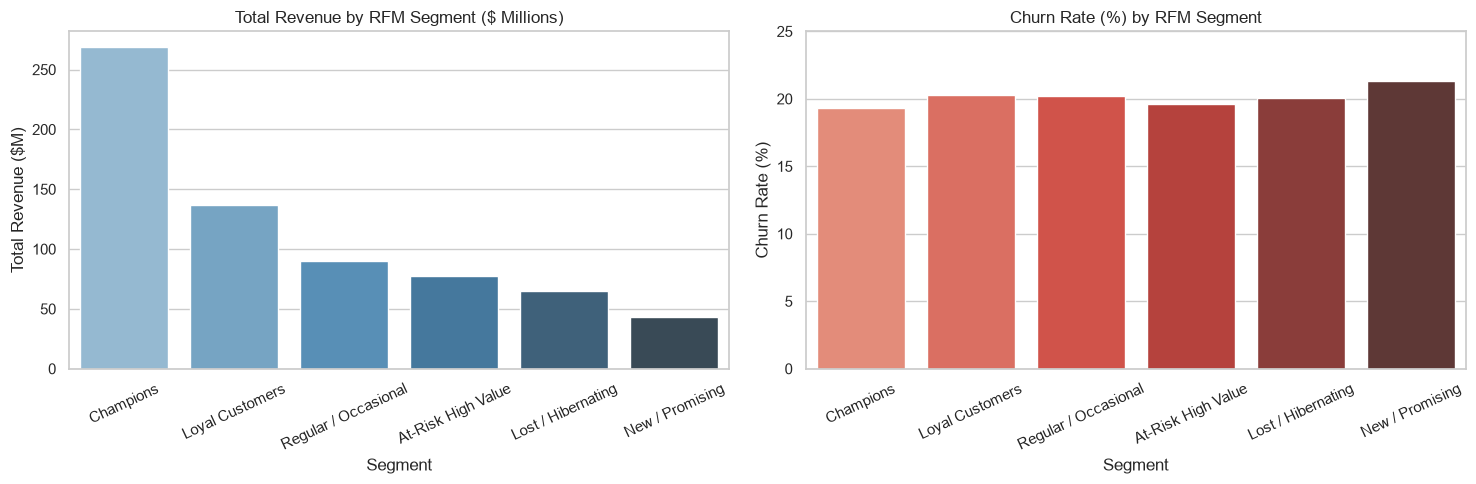

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
seg_order = segment_profile.index

# 1. Total Revenue by Segment ($M)
sns.barplot(x=seg_order, y=segment_profile["Total_Revenue"] / 1e6, ax=axes[0], hue=seg_order, palette="Blues_d", legend=False)
axes[0].set_title("Total Revenue by RFM Segment ($ Millions)")
axes[0].set_ylabel("Total Revenue ($M)")
axes[0].tick_params(axis="x", rotation=25)

# 2. Churn Rate (%) by Segment
sns.barplot(x=seg_order, y=segment_profile["Churn_Rate_Pct"], ax=axes[1], hue=seg_order, palette="Reds_d", legend=False)
axes[1].set_title("Churn Rate (%) by RFM Segment")
axes[1].set_ylabel("Churn Rate (%)")
axes[1].set_ylim(0, 25)
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.savefig("chart_segments_churn.png", dpi=300)
plt.show()

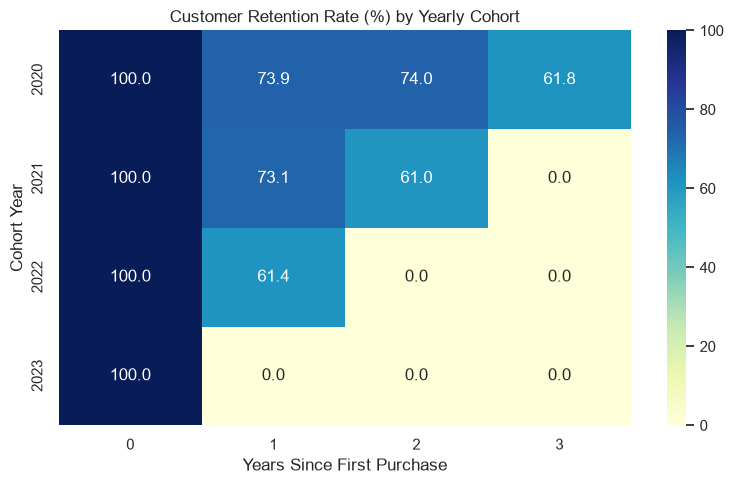

Repeat Purchase Rate (2+ Orders): 96.61%
Average Orders per Customer: 5.03

--- COHORT RETENTION (%) ---
Cohort_Index      0      1      2      3
Cohort_Year                             
2020          100.0  73.86  73.97  61.81
2021          100.0  73.12  60.95   0.00
2022          100.0  61.37   0.00   0.00
2023          100.0   0.00   0.00   0.00


In [7]:
# Build yearly cohort retention matrix
df["Cohort_Year"] = df.groupby("Customer ID")["Purchase Date"].transform("min").dt.year
df["Purchase_Year"] = df["Purchase Date"].dt.year
df["Cohort_Index"] = df["Purchase_Year"] - df["Cohort_Year"]

cohort_counts = df.groupby(["Cohort_Year", "Cohort_Index"])["Customer ID"].nunique().unstack(fill_value=0)
cohort_retention = cohort_counts.divide(cohort_counts.iloc[:, 0], axis=0) * 100

plt.figure(figsize=(8, 5))
sns.heatmap(cohort_retention, annot=True, fmt=".1f", cmap="YlGnBu")
plt.title("Customer Retention Rate (%) by Yearly Cohort")
plt.xlabel("Years Since First Purchase")
plt.ylabel("Cohort Year")
plt.tight_layout()
plt.savefig("chart_cohort_retention.png", dpi=300)
plt.show()

repeat_rate = (rfm["Frequency"] > 1).mean() * 100
print(f"Repeat Purchase Rate (2+ Orders): {repeat_rate:.2f}%")
print(f"Average Orders per Customer: {rfm['Frequency'].mean():.2f}")
print("\n--- COHORT RETENTION (%) ---")
print(cohort_retention.round(2))

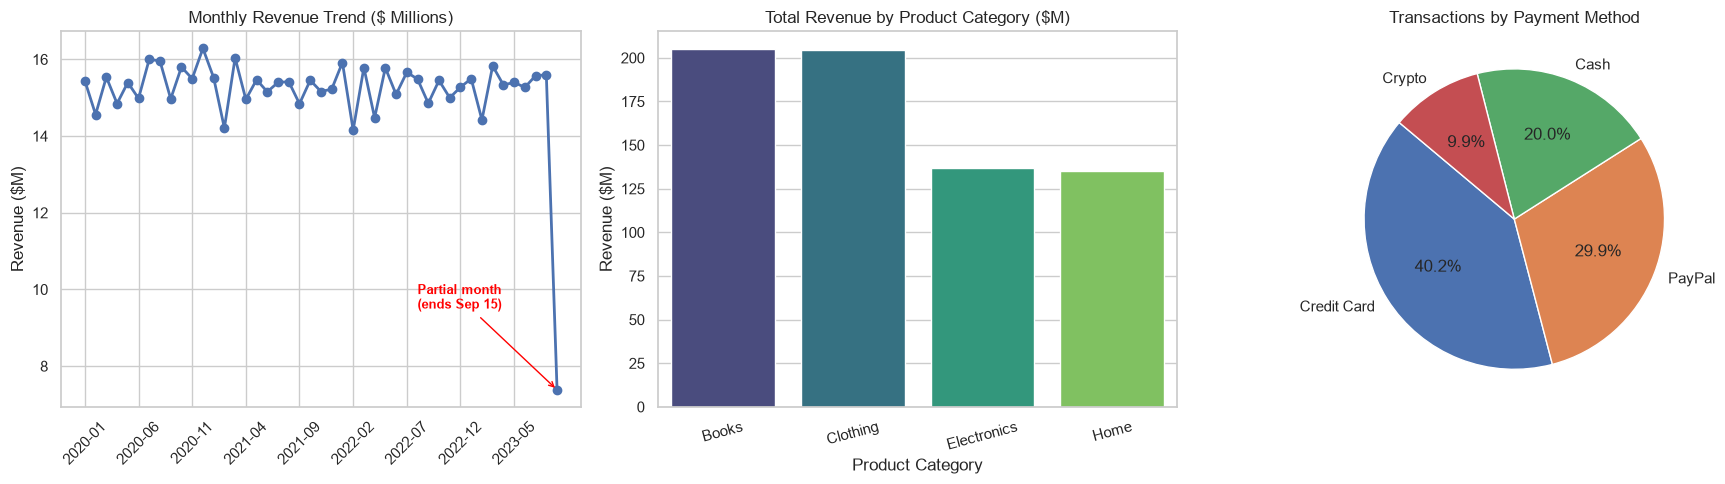

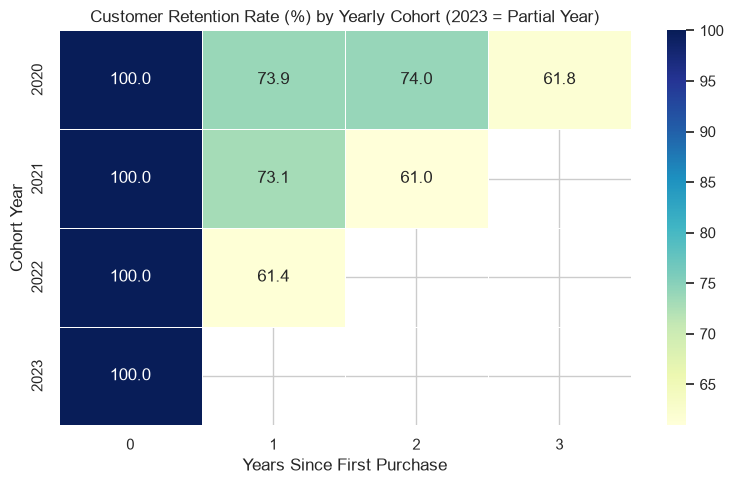

In [8]:
# 1. Re-save Monthly Revenue + Category + Payment with Partial Month Annotation
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

monthly_sales = df.groupby("YearMonth")["Total Purchase Amount"].sum().reset_index()
axes[0].plot(monthly_sales["YearMonth"], monthly_sales["Total Purchase Amount"] / 1e6, marker="o", linewidth=2)
axes[0].annotate(
    "Partial month\n(ends Sep 15)",
    xy=(len(monthly_sales) - 1, monthly_sales["Total Purchase Amount"].iloc[-1] / 1e6),
    xytext=(len(monthly_sales) - 14, 9.5),
    arrowprops=dict(arrowstyle="->", color="red"),
    fontsize=9, color="red", fontweight="bold"
)
axes[0].set_title("Monthly Revenue Trend ($ Millions)")
axes[0].set_ylabel("Revenue ($M)")
axes[0].set_xticks(range(0, len(monthly_sales), 5))
axes[0].set_xticklabels(monthly_sales["YearMonth"].iloc[::5], rotation=45)

cat_sales = df.groupby("Product Category")["Total Purchase Amount"].sum().sort_values(ascending=False)
sns.barplot(x=cat_sales.index, y=cat_sales.values / 1e6, ax=axes[1], hue=cat_sales.index, palette="viridis", legend=False)
axes[1].set_title("Total Revenue by Product Category ($M)")
axes[1].set_ylabel("Revenue ($M)")
axes[1].tick_params(axis="x", rotation=15)

pay_counts = df["Payment Method"].value_counts()
axes[2].pie(pay_counts.values, labels=pay_counts.index, autopct="%1.1f%%", startangle=140)
axes[2].set_title("Transactions by Payment Method")

plt.tight_layout()
plt.savefig("chart_purchase_patterns.png", dpi=300)
plt.show()

# 2. Re-save Cohort Retention Heatmap without misleading 0.0 future cells
cohort_counts_clean = df.groupby(["Cohort_Year", "Cohort_Index"])["Customer ID"].nunique().unstack()
cohort_retention_clean = cohort_counts_clean.divide(cohort_counts_clean.iloc[:, 0], axis=0) * 100

plt.figure(figsize=(8, 5))
sns.heatmap(cohort_retention_clean, annot=True, fmt=".1f", cmap="YlGnBu", linewidths=0.5)
plt.title("Customer Retention Rate (%) by Yearly Cohort (2023 = Partial Year)")
plt.xlabel("Years Since First Purchase")
plt.ylabel("Cohort Year")
plt.tight_layout()
plt.savefig("chart_cohort_retention.png", dpi=300)
plt.show()

In [9]:
from fpdf import FPDF

class ExecutiveReport(FPDF):
    def header(self):
        if self.page_no() > 1:
            self.set_font("Helvetica", "I", 8)
            self.set_text_color(110, 110, 110)
            self.cell(0, 8, "Alfido Tech | Task 1: Customer Behavior Analysis Report", align="R", new_x="LMARGIN", new_y="NEXT")
            self.ln(2)

    def footer(self):
        self.set_y(-15)
        self.set_font("Helvetica", "I", 8)
        self.set_text_color(120, 120, 120)
        self.cell(0, 10, f"Page {self.page_no()}", align="C")

    def section_title(self, title):
        self.set_font("Helvetica", "B", 13)
        self.set_text_color(24, 58, 107)
        self.cell(0, 9, title, new_x="LMARGIN", new_y="NEXT")
        self.set_draw_color(24, 58, 107)
        self.line(15, self.get_y(), 195, self.get_y())
        self.ln(4)

    def body_text(self, text):
        self.set_font("Helvetica", "", 10)
        self.set_text_color(40, 40, 40)
        self.multi_cell(0, 5.5, text)
        self.ln(2)

# Pull exact live metrics from your notebook
total_rev = df["Total Purchase Amount"].sum()
unique_cust = df["Customer ID"].nunique()
total_tx = len(df)
aov = df["Total Purchase Amount"].mean()
ret_rate = df["Returns"].mean() * 100
churn_rate = df.groupby("Customer ID")["Churn"].max().mean() * 100
repeat_rate = (rfm["Frequency"] > 1).mean() * 100
top_cat = cat_summary.index[0]
top_cat_rev = cat_summary.iloc[0]["Revenue"] / 1e6
second_cat = cat_summary.index[1]
second_cat_rev = cat_summary.iloc[1]["Revenue"] / 1e6

champ_rev_share = segment_profile.loc["Champions", "Revenue_Share_Pct"]
loyal_rev_share = segment_profile.loc["Loyal Customers", "Revenue_Share_Pct"]
atrisk_count = int(segment_profile.loc["At-Risk High Value", "Customers"])
atrisk_rev = segment_profile.loc["At-Risk High Value", "Total_Revenue"] / 1e6
atrisk_rec = segment_profile.loc["At-Risk High Value", "Avg_Recency"]
new_churn = segment_profile.loc["New / Promising", "Churn_Rate_Pct"]
new_ret = segment_profile.loc["New / Promising", "Return_Rate_Pct"]

pdf = ExecutiveReport()
pdf.set_auto_page_break(auto=True, margin=15)
pdf.set_margins(15, 15, 15)

# ================= PAGE 1: TITLE, EXEC SUMMARY & CLEANING =================
pdf.add_page()
pdf.set_fill_color(24, 58, 107)
pdf.rect(0, 0, 210, 42, "F")
pdf.set_y(10)
pdf.set_font("Helvetica", "B", 20)
pdf.set_text_color(255, 255, 255)
pdf.cell(0, 10, "Customer Behavior Analysis Report", align="L", new_x="LMARGIN", new_y="NEXT")
pdf.set_font("Helvetica", "", 11)
pdf.cell(0, 7, "Alfido Tech Data Analytics Internship - Task 1 | Prepared by Aniket Ninawe", align="L", new_x="LMARGIN", new_y="NEXT")
pdf.ln(14)

pdf.section_title("1. Executive Summary & Headline KPIs")
pdf.body_text(
    f"This report analyzes {total_tx:,} e-commerce transactions across {unique_cust:,} unique customers "
    f"(January 2020 to September 15, 2023) to uncover customer segments, purchasing trends, retention dynamics, "
    f"and churn risks for Alfido Tech. Total revenue reached ${total_rev:,.2f} with an Average Order Value (AOV) "
    f"of ${aov:,.2f} and a strong repeat purchase rate of {repeat_rate:.2f}%. However, two critical risks require "
    f"immediate action: an overall customer churn rate of {churn_rate:.2f}% and an elevated platform-wide return "
    f"rate of {ret_rate:.2f}%."
)

# KPI Table
pdf.set_font("Helvetica", "B", 9.5)
pdf.set_fill_color(235, 241, 249)
pdf.set_text_color(24, 58, 107)
kpis = [
    ("Total Revenue", f"${total_rev/1e6:.2f}M", "Unique Customers", f"{unique_cust:,}"),
    ("Total Transactions", f"{total_tx:,}", "Average Order Value", f"${aov:,.2f}"),
    ("Repeat Purchase Rate", f"{repeat_rate:.2f}%", "Customer Churn Rate", f"{churn_rate:.2f}%"),
    ("Overall Return Rate", f"{ret_rate:.2f}%", "Top Categories", f"{top_cat} & {second_cat}")
]
for k1, v1, k2, v2 in kpis:
    pdf.set_font("Helvetica", "B", 9.5)
    pdf.cell(45, 8, k1, border=1, fill=True)
    pdf.set_font("Helvetica", "", 9.5)
    pdf.set_text_color(30, 30, 30)
    pdf.cell(45, 8, v1, border=1)
    pdf.set_font("Helvetica", "B", 9.5)
    pdf.set_text_color(24, 58, 107)
    pdf.cell(45, 8, k2, border=1, fill=True)
    pdf.set_font("Helvetica", "", 9.5)
    pdf.set_text_color(30, 30, 30)
    pdf.cell(45, 8, v2, border=1, new_x="LMARGIN", new_y="NEXT")
pdf.ln(5)

pdf.section_title("2. Data Cleaning & Methodology")
pdf.body_text(
    "- Missing Values: 47,596 missing values (~19%) in the 'Returns' column were imputed as 0 (no return recorded), leaving 0 missing entries across all 250,000 rows.\n"
    "- Redundancy Removal: Verified 'Age' was 100% identical to 'Customer Age' and dropped the duplicate column; confirmed 0 exact duplicate transaction rows.\n"
    "- Data Integrity Check: Verified 'Total Purchase Amount' against 'Product Price * Quantity' (99.98% variance due to synthetic cart-level totals) and standardized on 'Total Purchase Amount' as the official spend metric.\n"
    "- Feature Engineering & Modeling: Parsed transaction timestamps into Year, Month, YearMonth, and DayOfWeek; binned customer ages into 5 demographic brackets; built customer-level RFM (Recency, Frequency, Monetary) scores mapped into 6 segments and validated cluster structure using K-Means (K=4 via Elbow Method)."
)

# ================= PAGE 2: SEGMENT PROFILES =================
pdf.add_page()
pdf.section_title("3. Customer Segmentation & Segment Profiles (RFM + K-Means)")
pdf.body_text(
    f"Champions and Loyal Customers represent 43.65% of the customer base yet drive {champ_rev_share + loyal_rev_share:.2f}% "
    f"of total revenue. Meanwhile, {atrisk_count:,} 'At-Risk High Value' customers (${atrisk_rev:.2f}M historical revenue) "
    f"have gone an average of {atrisk_rec:.0f} days without ordering, and 'New / Promising' buyers exhibit the highest "
    f"churn rate ({new_churn:.2f}%) and return rate ({new_ret:.2f}%)."
)

# Segment Profile Table
cols = ["Segment", "Customers", "Cust %", "Avg Rec.", "Avg Freq.", "Avg Spend", "Rev %", "Churn %"]
widths = [38, 20, 17, 19, 19, 25, 19, 23]
pdf.set_font("Helvetica", "B", 8.5)
pdf.set_fill_color(24, 58, 107)
pdf.set_text_color(255, 255, 255)
for col, w in zip(cols, widths):
    pdf.cell(w, 8, col, border=1, align="C", fill=True)
pdf.ln()

pdf.set_font("Helvetica", "", 8.5)
pdf.set_text_color(30, 30, 30)
for idx, (seg, row) in enumerate(segment_profile.iterrows()):
    fill = idx % 2 == 1
    pdf.set_fill_color(245, 248, 252)
    vals = [
        str(seg),
        f"{int(row['Customers']):,}",
        f"{row['Customer_Share_Pct']:.1f}%",
        f"{row['Avg_Recency']:.0f}d",
        f"{row['Avg_Frequency']:.2f}",
        f"${row['Avg_Monetary']:,.0f}",
        f"{row['Revenue_Share_Pct']:.1f}%",
        f"{row['Churn_Rate_Pct']:.2f}%"
    ]
    for i, (val, w) in enumerate(zip(vals, widths)):
        align = "L" if i == 0 else "R"
        pdf.cell(w, 7, val, border=1, align=align, fill=fill)
    pdf.ln()

pdf.ln(5)
pdf.image("chart_segments_churn.png", w=180)
pdf.ln(2)
pdf.set_font("Helvetica", "I", 8.5)
pdf.set_text_color(90, 90, 90)
pdf.cell(0, 5, "Figure 1: Revenue concentration and churn distribution across the six RFM customer segments.", align="C", new_x="LMARGIN", new_y="NEXT")

# ================= PAGE 3: PURCHASE PATTERNS & RETENTION =================
pdf.add_page()
pdf.section_title("4. Purchase Patterns & Retention Trends")
pdf.body_text(
    f"- Stable Monthly Demand: Revenue averaged $14M-$16M per month from Jan 2020 through Aug 2023. The apparent drop "
    f"in Sep 2023 reflects a partial reporting month ending Sep 15, 2023.\n"
    f"- Category & Payment Concentration: {top_cat} (${top_cat_rev:.1f}M) and {second_cat} (${second_cat_rev:.1f}M) "
    f"lead revenue, significantly ahead of Electronics and Home. Credit Card (40.2%) and PayPal (29.9%) capture 70.1% of transactions."
)
pdf.image("chart_purchase_patterns.png", w=180)
pdf.ln(4)

pdf.body_text(
    "- Cohort Retention Strength: Full-year retention held strongly at 73.9% (Year 1) and 74.0% (Year 2) for the 2020 cohort "
    "and 73.1% (Year 1) for the 2021 cohort. Lower figures across the 2023 diagonal (61.0%-61.8%) reflect the partial 2023 data window."
)
pdf.image("chart_cohort_retention.png", x=35, w=135)

# ================= PAGE 4: 5 ACTIONABLE RECOMMENDATIONS =================
pdf.add_page()
pdf.section_title("5. Five Actionable Recommendations for Alfido Tech")
pdf.body_text("Based on the segmentation, purchase patterns, and retention analysis, Alfido Tech should execute these five targeted initiatives:")

recs = [
    (
        "1. Launch an Automated Win-Back Campaign for 'At-Risk High Value' Customers",
        f"Target the {atrisk_count:,} At-Risk High Value customers representing ${atrisk_rev:.2f}M in historical spend "
        f"(inactive ~{atrisk_rec:.0f} days). Deploy a 3-step email/SMS re-engagement sequence offering a tiered 10%-15% "
        f"comeback voucher triggered automatically whenever a high-value customer crosses 180 days of inactivity."
    ),
    (
        "2. Fix Early-Stage Onboarding for 'New / Promising' Buyers to Curb Peak Churn",
        f"New / Promising customers have the highest churn rate ({new_churn:.2f}%) and highest return rate ({new_ret:.2f}%) "
        f"despite recent activity. Introduce a 30-day post-purchase onboarding sequence with product-care tips, proactive "
        f"support check-ins, and a personalized second-order incentive to convert one-time shoppers into Loyal Customers."
    ),
    (
        "3. Audit Product Quality & Sizing to Cut the Systemic ~40% Return Rate",
        f"Because return rates sit uniformly near {ret_rate:.2f}% across every segment (39.4%-40.7%), the issue is operational "
        f"rather than segment-specific. Prioritize listing accuracy, verified customer reviews, and packaging/QC audits - "
        f"especially in high-volume Clothing and Books - to reduce reverse-logistics cost and return-driven churn."
    ),
    (
        "4. Introduce a VIP Loyalty Program to Protect Top Revenue Drivers",
        f"Champions and Loyal Customers generate {champ_rev_share + loyal_rev_share:.2f}% of total revenue. Protect this core "
        f"with an invite-only VIP tier offering free expedited shipping, early access to new drops, and points multipliers "
        f"to raise switching costs and maintain >73% multi-year retention."
    ),
    (
        "5. Cross-Sell Underperforming Categories & Optimize Digital Checkout",
        f"Bundle lower-revenue Electronics and Home items with top-selling {top_cat} and {second_cat} orders via cart-page "
        f"recommendations. Since Credit Card and PayPal power 70.1% of orders, prioritize one-click digital checkout and "
        f"saved-card flows to minimize cart abandonment."
    )
]

for title, desc in recs:
    pdf.set_font("Helvetica", "B", 10.5)
    pdf.set_text_color(24, 58, 107)
    pdf.cell(0, 7, title, new_x="LMARGIN", new_y="NEXT")
    pdf.set_font("Helvetica", "", 10)
    pdf.set_text_color(40, 40, 40)
    pdf.multi_cell(0, 5.5, desc)
    pdf.ln(3)

output_pdf = "Alfido_Tech_Task1_Customer_Behavior_Report.pdf"
pdf.output(output_pdf)
print(f"PDF Report successfully generated: {output_pdf}")

PDF Report successfully generated: Alfido_Tech_Task1_Customer_Behavior_Report.pdf
